# Energy-Loss Analysis, Maintenance Priorities and CO₂ Impact

Turns the regression output into the sustainability results of the project:

1. How much clean energy the turbine lost in 2018, and the equivalent CO₂.
2. Which suspected operating states the loss comes from, and which individual stops.
3. When (month), at what wind speed, and from which wind direction the loss happens.
4. A ranked (Pareto) list of the conditions that cause most of the loss.
5. CO₂ scenarios for recovering part of the loss.

**Input:** `out/03_regression/model_results.csv` · **Outputs:** `out/04_loss_analysis/` and `figures/fig7-*`.

Loss is reported against **two baselines**:

- **Manufacturer baseline** – the theoretical power curve. Ideal test conditions, so it gives the *upper* estimate.
- **ML baseline** – the healthy power curve learned from this turbine's own normal-state data, giving the *realistic recoverable* estimate.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

INPUT_PATH = Path("../out/03_regression/model_results.csv")
OUT_DIR = Path("../out/04_loss_analysis")
FIG_DIR = Path("../figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)

HOURS_PER_RECORD = 1 / 6      # each record is a 10-minute average
CO2_FACTOR = 0.740            # tCO2 per MWh, Peninsular Malaysia grid (2024, provisional)
OPERATING_WS = 3.5            # m/s
LONG_STOP_HOURS = 6
TOP_N = 15                    # conditions shown in the Pareto chart
TOP_PRIORITY = 10             # conditions in the maintenance priority list

COLOR_ML, COLOR_MANUF, COLOR_MUTED = "#2a78d6", "#eb6834", "#8a8984"
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
STATE_LABELS = {
    "zero_output": "Zero output (shutdown-like)",
    "underperforming": "Underperforming",
    "near_curve": "Near curve (normal)",
    "below_operating_range": "Below operating range",
}
FOCUS = {
    "zero_output": "Review stop/fault logs; unplanned shutdowns in good wind",
    "underperforming": "Check yaw alignment, blades, pitch and anemometer",
    "near_curve": "Check power limitation / curtailment near rated wind",
    "below_operating_range": "Low wind; no action",
}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": COLOR_MUTED,
})
pd.options.display.float_format = "{:,.1f}".format


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()


df = pd.read_csv(INPUT_PATH, parse_dates=["timestamp"])
print("Records:", f"{len(df):,}")

Records: 50,530


## 1. Correcting the ML baseline below the operating range

The regression model was trained only on records with wind speed ≥ 3.5 m/s. Tree-based models cannot extrapolate, so below that range the model repeats the nearest value it learned (about 43 kW even with **no wind at all**), which creates loss that cannot be real.

In [2]:
below = df[~df["in_operating_region"]]
(below.groupby(pd.cut(below["wind_speed"], [0, 1, 2, 3, OPERATING_WS], include_lowest=True), observed=True)
 .agg(records=("power_kw", "size"),
      mean_actual_kw=("power_kw", "mean"),
      mean_manufacturer_kw=("theo_power_kw", "mean"),
      mean_ml_predicted_kw=("predicted_power_kw", "mean"),
      ml_loss_mwh_uncorrected=("ml_shortfall_kwh", lambda s: s.sum() / 1000)))

,records,mean_actual_kw,mean_manufacturer_kw,mean_ml_predicted_kw,ml_loss_mwh_uncorrected
wind_speed,,,,,
"(-0.001, 1.0]",824,0.0,0.0,42.6,5.9
"(1.0, 2.0]",2779,0.0,0.0,43.8,20.3
"(2.0, 3.0]",4146,0.9,0.0,43.4,29.4
"(3.0, 3.5]",2146,11.1,30.0,42.9,12.5


**Rule applied:** the ML baseline is used only inside the operating region, where the model was trained. Below it, the manufacturer curve is the expected output (already near zero there). All results below use this corrected ML baseline.

In [3]:
def loss_kwh(expected_kw):
    """Energy lost per record: only shortfalls count."""
    return (expected_kw - df["power_kw"]).clip(lower=0) * HOURS_PER_RECORD


df["exp_ml_kw"] = df["predicted_power_kw"].where(df["in_operating_region"], df["theo_power_kw"])
df["exp_ml_kwh"] = df["exp_ml_kw"] * HOURS_PER_RECORD
df["actual_kwh"] = df["power_kw"].clip(lower=0) * HOURS_PER_RECORD
df["loss_manuf_kwh"] = loss_kwh(df["theo_power_kw"])
df["loss_ml_kwh"] = loss_kwh(df["exp_ml_kw"])

print(f"ML loss before correction  : {df['ml_shortfall_kwh'].sum() / 1000:,.1f} MWh")
print(f"ML loss after correction   : {df['loss_ml_kwh'].sum() / 1000:,.1f} MWh")
print(f"Manufacturer-baseline loss : {df['loss_manuf_kwh'].sum() / 1000:,.1f} MWh")

ML loss before correction  : 677.9 MWh
ML loss after correction   : 617.5 MWh
Manufacturer-baseline loss : 1,600.0 MWh


## 2. Headline: energy and CO₂ lost in 2018

*Potential output* is what the turbine would have produced if every shortfall had been recovered: actual energy + loss. Loss share = loss ÷ potential output.

In [4]:
def loss_summary(loss_kwh_total, actual_kwh_total):
    loss_mwh = loss_kwh_total / 1000
    potential_mwh = (actual_kwh_total + loss_kwh_total) / 1000
    return loss_mwh, 100 * loss_mwh / potential_mwh, loss_mwh * CO2_FACTOR


actual_mwh = df["actual_kwh"].sum() / 1000
m_mwh, m_pct, m_co2 = loss_summary(df["loss_manuf_kwh"].sum(), df["actual_kwh"].sum())
l_mwh, l_pct, l_co2 = loss_summary(df["loss_ml_kwh"].sum(), df["actual_kwh"].sum())

zero = df["rule_state"] == "zero_output"
zero_hours = zero.sum() * HOURS_PER_RECORD

headline = pd.DataFrame({
    "measure": [
        "Actual energy generated (MWh)",
        "Energy lost (MWh)",
        "Loss as % of potential output",
        "Equivalent CO2 (tonnes)",
        f"Zero-output intervals with wind >= {OPERATING_WS} m/s",
        "Zero-output time (hours)",
    ],
    "manufacturer_baseline": [actual_mwh, m_mwh, m_pct, m_co2, zero.sum(), zero_hours],
    "ml_baseline": [actual_mwh, l_mwh, l_pct, l_co2, zero.sum(), zero_hours],
})
headline

,measure,manufacturer_baseline,ml_baseline
0,Actual energy generated (MWh),"11,012.9","11,012.9"
1,Energy lost (MWh),"1,600.0",617.5
2,Loss as % of potential output,12.7,5.3
3,Equivalent CO2 (tonnes),"1,184.0",456.9
4,Zero-output intervals with wind >= 3.5 m/s,"2,220.0","2,220.0"
5,Zero-output time (hours),370.0,370.0


### Sensitivity to the choice of healthy curve

A 0.5 m/s binned power curve was slightly more accurate than XGBoost in cross-validation (notebook 03). Using it as the healthy baseline instead shows how much the loss estimate depends on that choice.

In [5]:
loss_binned_kwh = loss_kwh(df["binned_power_kw"].where(df["in_operating_region"], df["theo_power_kw"]))
sensitivity = pd.DataFrame({
    "loss_mwh": [l_mwh, loss_binned_kwh.sum() / 1000],
    "zero_output_share_pct": [100 * df.loc[zero, "loss_ml_kwh"].sum() / df["loss_ml_kwh"].sum(),
                              100 * loss_binned_kwh[zero].sum() / loss_binned_kwh.sum()],
}, index=["XGBoost healthy curve", "Binned power curve (0.5 m/s)"])
sensitivity

,loss_mwh,zero_output_share_pct
XGBoost healthy curve,617.5,51.9
Binned power curve (0.5 m/s),703.2,54.9


## 3. Loss by suspected operating state

DBSCAN put 99.6 % of operating-region records into one cluster, so the clusters cannot split the loss into meaningful states (first table). The loss is therefore broken down by the **rule-based reference states** from notebook 01. These are suspected states, not confirmed faults.

In [6]:
def by_group(data, col, order=None):
    t = (data.groupby(col, observed=True)
         .agg(records=("power_kw", "size"),
              exp_ml_mwh=("exp_ml_kwh", "sum"),
              loss_ml_mwh=("loss_ml_kwh", "sum"),
              loss_manuf_mwh=("loss_manuf_kwh", "sum")))
    t[["exp_ml_mwh", "loss_ml_mwh", "loss_manuf_mwh"]] /= 1000
    t["hours"] = t["records"] * HOURS_PER_RECORD
    t["share_of_ml_loss_pct"] = 100 * t["loss_ml_mwh"] / t["loss_ml_mwh"].sum()
    t["share_of_manuf_loss_pct"] = 100 * t["loss_manuf_mwh"] / t["loss_manuf_mwh"].sum()
    t["ml_loss_rate_pct"] = 100 * t["loss_ml_mwh"] / t["exp_ml_mwh"].where(t["exp_ml_mwh"] > 0)
    t["co2_ml_t"] = t["loss_ml_mwh"] * CO2_FACTOR
    t["co2_manuf_t"] = t["loss_manuf_mwh"] * CO2_FACTOR
    if order is not None:
        t = t.reindex([o for o in order if o in t.index])
    return t[["records", "hours", "loss_ml_mwh", "loss_manuf_mwh",
              "share_of_ml_loss_pct", "share_of_manuf_loss_pct",
              "ml_loss_rate_pct", "co2_ml_t", "co2_manuf_t"]]


by_group(df, "cluster_state")[["records", "loss_ml_mwh", "loss_manuf_mwh", "share_of_ml_loss_pct"]]

,records,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct
cluster_state,,,,
0,40476,556.2,"1,533.4",90.1
1,42,21.3,22.3,3.4
2,10,4.3,4.4,0.7
3,8,3.6,3.8,0.6
below_operating_range,9895,7.6,7.6,1.2
dbscan_noise,99,24.4,28.5,4.0


In [7]:
state_table = by_group(df, "rule_state", order=list(STATE_LABELS))
state_table.index = state_table.index.map(STATE_LABELS)
state_table

,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
rule_state,,,,,,,,,
Zero output (shutdown-like),2220,370.0,320.6,456.1,51.9,28.5,100.0,237.2,337.5
Underperforming,7218,"1,203.0",215.5,436.0,34.9,27.3,23.9,159.4,322.7
Near curve (normal),31197,"5,199.5",73.8,700.2,12.0,43.8,0.7,54.6,518.2
Below operating range,9895,"1,649.2",7.6,7.6,1.2,0.5,71.1,5.6,5.6


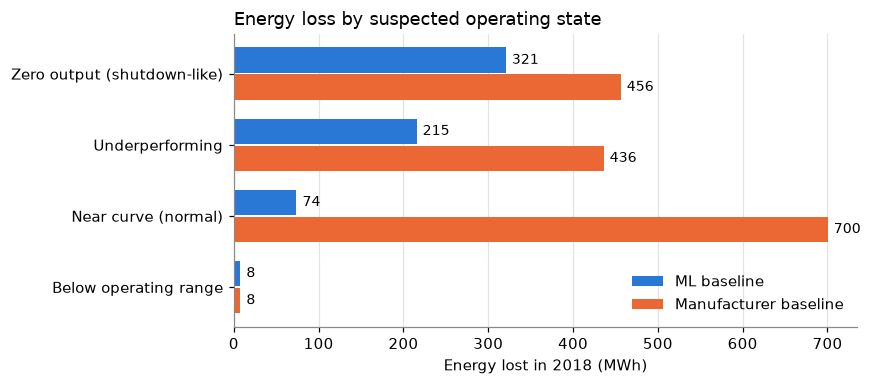

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(state_table))
h = 0.36
for offset, col, color, label in [(-1, "loss_ml_mwh", COLOR_ML, "ML baseline"),
                                  (1, "loss_manuf_mwh", COLOR_MANUF, "Manufacturer baseline")]:
    bars = ax.barh(y + offset * (h / 2 + 0.01), state_table[col], height=h, color=color, label=label)
    ax.bar_label(bars, fmt="{:,.0f}", padding=4, fontsize=9)
ax.set_yticks(y, state_table.index)
ax.invert_yaxis()
ax.set_xlabel("Energy lost in 2018 (MWh)")
ax.set_title("Energy loss by suspected operating state", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save_fig("fig7-1_loss_by_state.png")

Under the manufacturer curve, much of the loss sits in the "near curve" state: normal running slightly below an ideal curve. Under the ML baseline that part shrinks sharply, and what remains is concentrated in the **zero-output** and **underperforming** states, which maintenance can act on.

### Individual stops

A stop is a run of consecutive zero-output records in good wind (no missing interval in between). A few long stops carry most of the shutdown-like loss.

In [9]:
stop_id = (~zero | (df["gap_before_min"] > 10)).cumsum()
stops = (df[zero].groupby(stop_id[zero])
         .agg(start=("timestamp", "min"),
              end=("timestamp", "max"),
              records=("power_kw", "size"),
              mean_wind_ms=("wind_speed", "mean"),
              mean_expected_kw=("exp_ml_kw", "mean"),
              loss_ml_mwh=("loss_ml_kwh", "sum"),
              clusters=("cluster_state", lambda s: ", ".join(sorted(s.unique()))))
         .sort_values("records", ascending=False)
         .reset_index(drop=True))
stops["loss_ml_mwh"] /= 1000
stops["hours"] = stops["records"] * HOURS_PER_RECORD
stops["share_of_ml_loss_pct"] = 100 * stops["loss_ml_mwh"] / l_mwh

long_stops = stops[stops["hours"] >= LONG_STOP_HOURS]
print(f"{len(stops)} stops in total; {len(long_stops)} of {LONG_STOP_HOURS} hours or longer cause "
      f"{100 * long_stops['loss_ml_mwh'].sum() / stops['loss_ml_mwh'].sum():.0f}% of the shutdown-like loss")
longest = stops.iloc[0]
print(f"Longest stop: {longest['hours']:.1f} h from {longest['start']} to {longest['end']}, "
      f"{longest['loss_ml_mwh']:.0f} MWh = {longest['loss_ml_mwh'] * CO2_FACTOR:.0f} t CO2")
long_stops

476 stops in total; 13 of 6 hours or longer cause 67% of the shutdown-like loss
Longest stop: 44.5 h from 2018-01-24 06:10:00 to 2018-01-26 02:30:00, 77 MWh = 57 t CO2


,start,end,records,mean_wind_ms,mean_expected_kw,loss_ml_mwh,clusters,hours,share_of_ml_loss_pct
0,2018-01-24 06:10:00,2018-01-26 02:30:00,267,9.6,"1,725.2",76.8,0,44.5,12.4
1,2018-01-14 08:50:00,2018-01-15 06:30:00,131,7.1,916.2,20.0,0,21.8,3.2
2,2018-02-25 18:50:00,2018-02-26 10:20:00,94,8.9,"1,330.2",20.8,0,15.7,3.4
3,2018-12-04 21:40:00,2018-12-05 13:10:00,94,9.9,"1,399.2",21.9,0,15.7,3.6
4,2018-12-19 18:20:00,2018-12-20 08:20:00,85,6.1,539.9,7.6,0,14.2,1.2
5,2018-01-16 01:50:00,2018-01-16 10:20:00,52,14.5,"2,919.0",25.3,0,8.7,4.1
6,2018-02-28 18:50:00,2018-03-01 03:20:00,52,5.1,296.4,2.6,0,8.7,0.4
7,2018-02-22 06:00:00,2018-02-22 14:20:00,51,7.8,"1,224.7",10.4,0,8.5,1.7
8,2018-02-23 06:10:00,2018-02-23 14:20:00,50,9.5,"1,971.9",16.4,0,8.3,2.7
9,2018-12-29 08:00:00,2018-12-29 14:40:00,41,7.0,828.9,5.7,0,6.8,0.9


## 4. When the loss happens: by month

Total loss is partly driven by how windy a month is; the **loss rate** (loss ÷ expected ML energy) shows in which months the turbine performed worst relative to what it could have produced.

In [10]:
month_table = by_group(df, "month_name", order=MONTHS)
month_table

,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
month_name,,,,,,,,,
Jan,3817,636.2,226.5,341.1,36.7,21.3,22.1,167.6,252.4
Feb,4032,672.0,84.8,148.8,13.7,9.3,8.2,62.7,110.1
Mar,4463,743.8,35.2,95.1,5.7,5.9,2.5,26.0,70.4
Apr,4305,717.5,31.1,96.9,5.0,6.1,5.2,23.0,71.7
May,4449,741.5,19.5,92.4,3.2,5.8,3.3,14.4,68.4
Jun,4245,707.5,18.9,102.7,3.1,6.4,2.7,14.0,76.0
Jul,4464,744.0,16.0,79.9,2.6,5.0,4.5,11.9,59.1
Aug,4425,737.5,36.7,179.7,5.9,11.2,2.5,27.1,133.0
Sep,4000,666.7,12.1,84.4,2.0,5.3,1.3,8.9,62.5


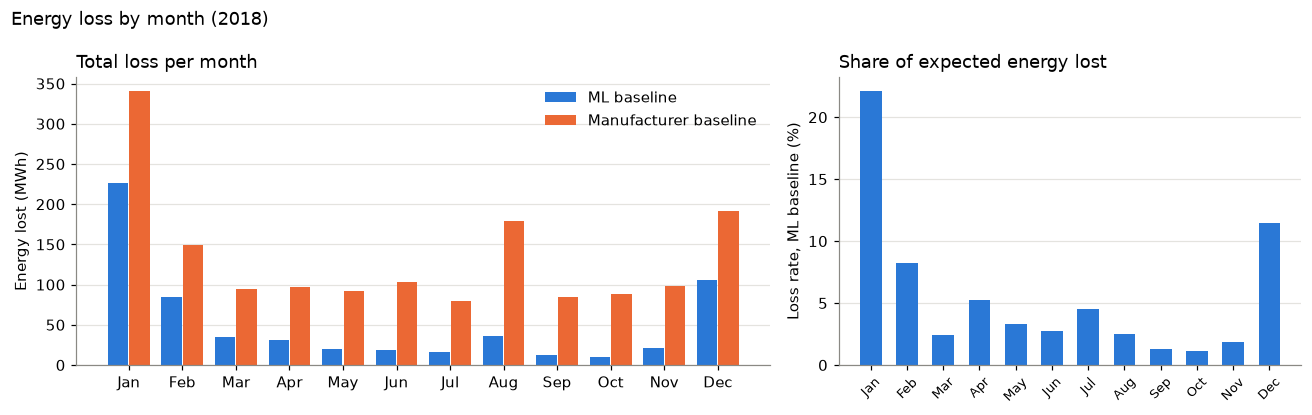

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [3, 2]})
x = np.arange(len(month_table))
w = 0.38
ax = axes[0]
ax.bar(x - w / 2 - 0.01, month_table["loss_ml_mwh"], width=w, color=COLOR_ML, label="ML baseline")
ax.bar(x + w / 2 + 0.01, month_table["loss_manuf_mwh"], width=w, color=COLOR_MANUF, label="Manufacturer baseline")
ax.set_xticks(x, month_table.index)
ax.set_ylabel("Energy lost (MWh)")
ax.set_title("Total loss per month", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)

ax = axes[1]
ax.bar(x, month_table["ml_loss_rate_pct"], width=0.6, color=COLOR_ML)
ax.set_xticks(x, month_table.index, fontsize=8.5, rotation=45)
ax.set_ylabel("Loss rate, ML baseline (%)")
ax.set_title("Share of expected energy lost", loc="left")
ax.grid(axis="x", visible=False)
fig.suptitle("Energy loss by month (2018)", x=0.01, ha="left", fontsize=12)
save_fig("fig7-3_loss_by_month.png")

## 5. At what wind speed the loss happens

Loss per 0.5 m/s wind-speed bin. Losses in the middle of the curve point to underperformance; losses near and above rated wind speed point to power limitation or stops in strong wind.

In [12]:
ws_table = by_group(df, "ws_bin").sort_index()
ws_share = ws_table["share_of_ml_loss_pct"]
print(f"Share of ML loss between 8 and 11.5 m/s: {ws_share.loc[8:11].sum():.0f}%")
print(f"Share of ML loss at 15 m/s and above: {ws_share.loc[15:].sum():.0f}%")

rated_wind = df[df["wind_speed"] >= 13]
print(f"Records at 13 m/s or more below 3,500 kW: {100 * (rated_wind['power_kw'] < 3500).mean():.0f}%")
ws_table.loc[ws_table["loss_ml_mwh"] > 0.5]

Share of ML loss between 8 and 11.5 m/s: 48%
Share of ML loss at 15 m/s and above: 6%
Records at 13 m/s or more below 3,500 kW: 21%


,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
ws_bin,,,,,,,,,
3.0,2146,357.7,7.6,7.6,1.2,0.5,71.1,5.6,5.6
3.5,1931,321.8,6.9,12.4,1.1,0.8,35.8,5.1,9.2
4.0,2030,338.3,7.9,18.3,1.3,1.1,18.9,5.8,13.6
4.5,1888,314.7,8.0,20.9,1.3,1.3,11.7,5.9,15.5
5.0,1927,321.2,10.0,27.9,1.6,1.7,9.6,7.4,20.6
5.5,2214,369.0,14.2,39.9,2.3,2.5,8.6,10.5,29.5
6.0,2429,404.8,21.0,55.8,3.4,3.5,8.9,15.5,41.3
6.5,2452,408.7,25.0,62.8,4.1,3.9,8.0,18.5,46.5
7.0,2411,401.8,29.4,72.8,4.8,4.6,7.6,21.8,53.9


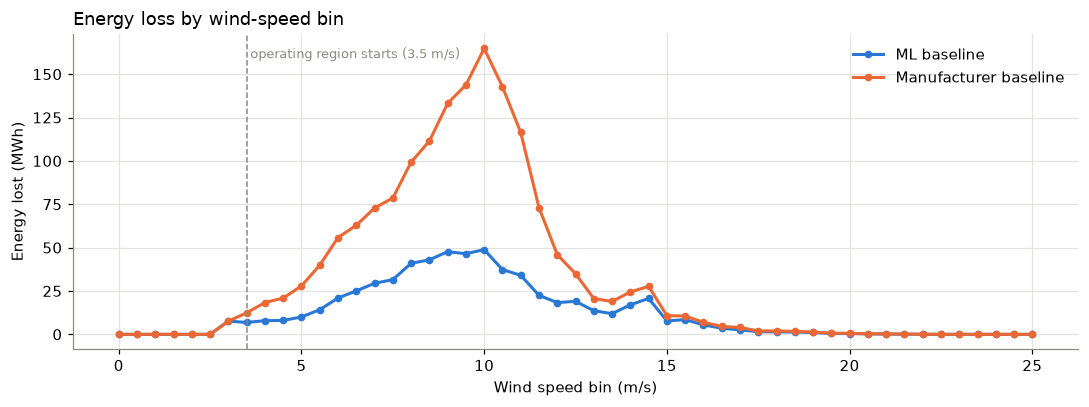

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ws_table.index, ws_table["loss_ml_mwh"], color=COLOR_ML, lw=2, marker="o", ms=4, label="ML baseline")
ax.plot(ws_table.index, ws_table["loss_manuf_mwh"], color=COLOR_MANUF, lw=2, marker="o", ms=4,
        label="Manufacturer baseline")
ax.axvline(OPERATING_WS, color=COLOR_MUTED, lw=1, ls="--")
ax.text(OPERATING_WS + 0.1, ax.get_ylim()[1] * 0.92, f"operating region starts ({OPERATING_WS} m/s)",
        color=COLOR_MUTED, fontsize=8.5)
ax.set_xlabel("Wind speed bin (m/s)")
ax.set_ylabel("Energy lost (MWh)")
ax.set_title("Energy loss by wind-speed bin", loc="left")
ax.legend(frameon=False)
save_fig("fig7-5_loss_by_wind_speed.png")

## 6. Which wind direction the loss comes from

Loss per 30° sector (direction the wind blows **from**). A sector with a high loss rate can point to yaw misalignment, wake or terrain effects. Sectors with few hours of wind (for example 90–120°, about 250 hours) give less reliable rates, so check the `hours` column before drawing conclusions.

In [14]:
dir_order = (df[["dir_sector_start", "dir_sector"]].drop_duplicates()
             .sort_values("dir_sector_start")["dir_sector"].tolist())
dir_table = by_group(df, "dir_sector", order=dir_order)
dir_table

,records,hours,loss_ml_mwh,loss_manuf_mwh,share_of_ml_loss_pct,share_of_manuf_loss_pct,ml_loss_rate_pct,co2_ml_t,co2_manuf_t
dir_sector,,,,,,,,,
0–30°,5216,869.3,113.8,245.6,18.4,15.3,13.9,84.2,181.7
30–60°,12569,"2,094.8",210.8,504.7,34.1,31.5,7.1,156.0,373.5
60–90°,10592,"1,765.3",97.6,388.5,15.8,24.3,3.8,72.2,287.5
90–120°,1497,249.5,7.0,9.3,1.1,0.6,15.8,5.2,6.9
120–150°,995,165.8,3.3,12.4,0.5,0.8,5.4,2.4,9.2
150–180°,1626,271.0,8.6,23.6,1.4,1.5,2.6,6.4,17.4
180–210°,7686,"1,281.0",88.5,202.5,14.3,12.7,3.1,65.5,149.8
210–240°,3902,650.3,43.5,106.1,7.1,6.6,4.5,32.2,78.5
240–270°,2305,384.2,21.3,53.9,3.5,3.4,10.0,15.8,39.9


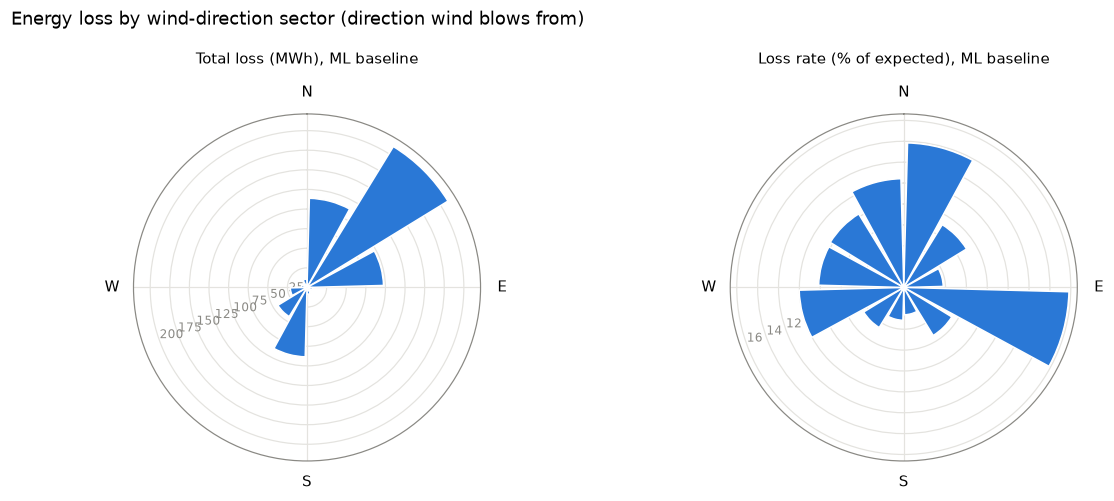

In [15]:
fig = plt.figure(figsize=(11, 4.6))
theta = np.deg2rad(np.arange(0, 360, 30) + 15)
panels = [("loss_ml_mwh", "Total loss (MWh)"), ("ml_loss_rate_pct", "Loss rate (% of expected)")]
for k, (col, title) in enumerate(panels, start=1):
    ax = fig.add_subplot(1, 2, k, projection="polar")
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.bar(theta, dir_table[col].reindex(dir_order).fillna(0), width=np.deg2rad(30) * 0.9,
           color=COLOR_ML, edgecolor="white", linewidth=1)
    ax.set_title(title + ", ML baseline", fontsize=10, pad=14)
    ax.set_xticks(np.deg2rad([0, 90, 180, 270]), ["N", "E", "S", "W"])
    ax.set_rlabel_position(250)
    ax.tick_params(axis="y", labelsize=8, colors=COLOR_MUTED)
    ax.grid(color="#e4e3df")
fig.suptitle("Energy loss by wind-direction sector (direction wind blows from)", x=0.01, ha="left", fontsize=12)
save_fig("fig7-4_loss_by_direction.png")

## 7. Pareto ranking: where to look first

Each month × direction-sector combination is one "condition". Conditions are ranked by ML-baseline loss, and the cumulative share shows how few of them account for most of the loss.

In [16]:
cond = (df.groupby(["month", "month_name", "dir_sector"], observed=True)
        .agg(records=("power_kw", "size"),
             mean_wind_ms=("wind_speed", "mean"),
             loss_ml_mwh=("loss_ml_kwh", "sum"),
             loss_manuf_mwh=("loss_manuf_kwh", "sum"))
        .reset_index())
cond[["loss_ml_mwh", "loss_manuf_mwh"]] /= 1000
cond = cond[cond["loss_ml_mwh"] > 0].sort_values("loss_ml_mwh", ascending=False).reset_index(drop=True)
cond["rank"] = cond.index + 1
cond["share_pct"] = 100 * cond["loss_ml_mwh"] / cond["loss_ml_mwh"].sum()
cond["cumulative_pct"] = cond["share_pct"].cumsum()
cond["condition"] = cond["month_name"] + " · " + cond["dir_sector"]

n50 = int((cond["cumulative_pct"] < 50).sum() + 1)
n80 = int((cond["cumulative_pct"] < 80).sum() + 1)
print(f"Conditions with any loss: {len(cond)}")
print(f"{n50} conditions ({100 * n50 / len(cond):.0f}%) cause 50% of the ML-baseline loss")
print(f"{n80} conditions ({100 * n80 / len(cond):.0f}%) cause 80% of the ML-baseline loss")

Conditions with any loss: 134
6 conditions (4%) cause 50% of the ML-baseline loss
25 conditions (19%) cause 80% of the ML-baseline loss


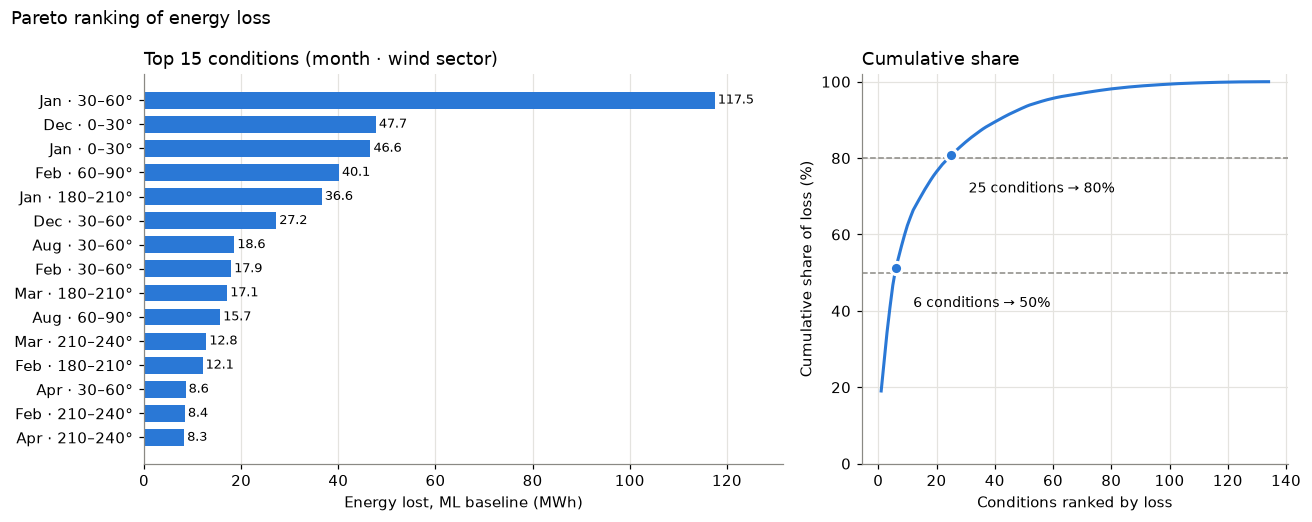

In [17]:
top = cond.head(TOP_N)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [3, 2]})

ax = axes[0]
bars = ax.barh(top["condition"], top["loss_ml_mwh"], color=COLOR_ML, height=0.7)
ax.bar_label(bars, fmt="{:,.1f}", padding=2, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(0, top["loss_ml_mwh"].max() * 1.12)
ax.set_xlabel("Energy lost, ML baseline (MWh)")
ax.set_title(f"Top {TOP_N} conditions (month · wind sector)", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.plot(cond["rank"], cond["cumulative_pct"], color=COLOR_ML, lw=2)
for n, p in [(n50, 50), (n80, 80)]:
    ax.axhline(p, color=COLOR_MUTED, lw=1, ls="--")
    ax.plot([n], [cond.loc[n - 1, "cumulative_pct"]], "o", color=COLOR_ML, ms=8,
            markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"{n} conditions → {p}%", (n, p), xytext=(n + 6, p - 9), fontsize=9)
ax.set_xlabel("Conditions ranked by loss")
ax.set_ylabel("Cumulative share of loss (%)")
ax.set_ylim(0, 102)
ax.set_title("Cumulative share", loc="left")
fig.suptitle("Pareto ranking of energy loss", x=0.01, ha="left", fontsize=12)
save_fig("fig7-2_pareto_loss.png")

### Maintenance priority list

For each top condition, the dominant suspected state (the one contributing most of its loss) suggests what to check first. This is an **inspection focus, not a diagnosis**; it must be confirmed against maintenance logs or on-site inspection.

In [18]:
state_loss = (df.groupby(["month_name", "dir_sector", "rule_state"], observed=True)["loss_ml_kwh"]
              .sum().unstack(fill_value=0))
state_share = state_loss.div(state_loss.sum(axis=1), axis=0)

priority = cond.head(TOP_PRIORITY).copy()
top_share = state_share.loc[list(zip(priority["month_name"], priority["dir_sector"]))]
priority["dominant_state"] = top_share.idxmax(axis=1).to_numpy()
priority["dominant_state_share_pct"] = 100 * top_share.max(axis=1).to_numpy()
priority["co2_ml_t"] = priority["loss_ml_mwh"] * CO2_FACTOR
priority["hours"] = priority["records"] * HOURS_PER_RECORD
priority["suggested_focus"] = priority["dominant_state"].map(FOCUS)
priority = priority[["rank", "month_name", "dir_sector", "hours", "mean_wind_ms",
                     "loss_ml_mwh", "loss_manuf_mwh", "share_pct", "cumulative_pct",
                     "co2_ml_t", "dominant_state", "dominant_state_share_pct", "suggested_focus"]]
priority

,rank,month_name,dir_sector,hours,mean_wind_ms,loss_ml_mwh,loss_manuf_mwh,share_pct,cumulative_pct,co2_ml_t,dominant_state,dominant_state_share_pct,suggested_focus
0,1,Jan,30–60°,99.0,9.2,117.5,153.4,19.0,19.0,86.9,zero_output,69.7,Review stop/fault logs; unplanned shutdowns in...
1,2,Dec,0–30°,124.3,9.5,47.7,87.5,7.7,26.8,35.3,underperforming,52.0,"Check yaw alignment, blades, pitch and anemometer"
2,3,Jan,0–30°,62.7,8.3,46.6,77.8,7.5,34.3,34.5,underperforming,51.5,"Check yaw alignment, blades, pitch and anemometer"
3,4,Feb,60–90°,151.0,7.7,40.1,70.0,6.5,40.8,29.7,zero_output,82.6,Review stop/fault logs; unplanned shutdowns in...
4,5,Jan,180–210°,196.3,11.3,36.6,56.4,5.9,46.7,27.1,zero_output,78.5,Review stop/fault logs; unplanned shutdowns in...
5,6,Dec,30–60°,79.5,6.2,27.2,37.9,4.4,51.1,20.1,underperforming,54.9,"Check yaw alignment, blades, pitch and anemometer"
6,7,Aug,30–60°,372.2,9.5,18.6,90.6,3.0,54.1,13.8,near_curve,38.7,Check power limitation / curtailment near rate...
7,8,Feb,30–60°,93.0,7.5,17.9,27.5,2.9,57.1,13.3,underperforming,75.4,"Check yaw alignment, blades, pitch and anemometer"
8,9,Mar,180–210°,330.2,11.8,17.1,46.4,2.8,59.8,12.7,near_curve,37.1,Check power limitation / curtailment near rate...
9,10,Aug,60–90°,263.0,10.1,15.7,73.3,2.5,62.4,11.6,near_curve,35.8,Check power limitation / curtailment near rate...


## 8. CO₂ scenarios

These are **estimates**, not measured savings. Each recovered MWh is assumed to displace grid electricity at Peninsular Malaysia's grid emission factor of 0.740 tCO₂/MWh (2024, provisional). The turbine is in Turkey; the Malaysian factor expresses the impact in a Malaysian context.

In [19]:
zero_ml = df.loc[zero, "loss_ml_kwh"].sum() / 1000
under_ml = df.loc[df["rule_state"] == "underperforming", "loss_ml_kwh"].sum() / 1000

scenarios = pd.DataFrame({
    "scenario": [
        "Recover all zero-output (shutdown-like) loss",
        "Recover zero-output + underperforming loss",
        "Recover 50% of ML-baseline loss",
        "Recover all ML-baseline loss (realistic ceiling)",
        "Recover 50% of manufacturer-baseline loss (proposal scenario)",
        "Recover all manufacturer-baseline loss (theoretical ceiling)",
    ],
    "energy_mwh": [zero_ml, zero_ml + under_ml, 0.5 * l_mwh, l_mwh, 0.5 * m_mwh, m_mwh],
})
scenarios["co2_avoided_t"] = scenarios["energy_mwh"] * CO2_FACTOR
scenarios["pct_of_actual_generation"] = 100 * scenarios["energy_mwh"] / actual_mwh
scenarios

,scenario,energy_mwh,co2_avoided_t,pct_of_actual_generation
0,Recover all zero-output (shutdown-like) loss,320.6,237.2,2.9
1,Recover zero-output + underperforming loss,536.1,396.7,4.9
2,Recover 50% of ML-baseline loss,308.7,228.5,2.8
3,Recover all ML-baseline loss (realistic ceiling),617.5,456.9,5.6
4,Recover 50% of manufacturer-baseline loss (pro...,800.0,592.0,7.3
5,Recover all manufacturer-baseline loss (theore...,"1,600.0","1,184.0",14.5


In [20]:
outputs = {
    "headline_loss.csv": (headline, False),
    "baseline_sensitivity.csv": (sensitivity, True),
    "loss_by_state.csv": (state_table, True),
    "loss_by_month.csv": (month_table, True),
    "loss_by_wind_speed.csv": (ws_table, True),
    "loss_by_direction.csv": (dir_table, True),
    "stop_events.csv": (stops, False),
    "pareto_conditions.csv": (cond, False),
    "maintenance_priority.csv": (priority, False),
    "co2_scenarios.csv": (scenarios, False),
}
for name, (table, keep_index) in outputs.items():
    table.to_csv(OUT_DIR / name, index=keep_index)
print("Saved:", *sorted(outputs), sep="\n  ")

Saved:
  baseline_sensitivity.csv
  co2_scenarios.csv
  headline_loss.csv
  loss_by_direction.csv
  loss_by_month.csv
  loss_by_state.csv
  loss_by_wind_speed.csv
  maintenance_priority.csv
  pareto_conditions.csv
  stop_events.csv


## 9. Key findings

In [21]:
top1 = cond.iloc[0]
zero_row, under_row = state_table.iloc[0], state_table.iloc[1]
jan_dec = month_table.loc[["Jan", "Dec"], "share_of_ml_loss_pct"].sum()
print(f"1. In 2018 the turbine lost {l_mwh:,.0f} MWh against its own healthy curve "
      f"({l_pct:.1f}% of potential output, ~{l_co2:,.0f} t CO2) and {m_mwh:,.0f} MWh against "
      f"the manufacturer curve ({m_pct:.1f}%, ~{m_co2:,.0f} t CO2).")
print(f"2. Zero-output (shutdown-like) periods in good wind cause {zero_row['share_of_ml_loss_pct']:.0f}% "
      f"of the realistic loss in only {zero_row['hours']:,.0f} hours; underperformance adds "
      f"{under_row['share_of_ml_loss_pct']:.0f}%.")
print(f"3. January and December together account for {jan_dec:.0f}% of the realistic loss.")
print(f"4. {n50} of {len(cond)} month-sector conditions cause half of the loss; the single largest is "
      f"{top1['condition']} ({top1['loss_ml_mwh']:,.0f} MWh, {top1['share_pct']:.0f}%).")
print(f"5. The longest stop ({longest['hours']:.1f} h) alone accounts for {longest['share_of_ml_loss_pct']:.0f}% "
      f"of the realistic loss.")
print(f"6. Recovering only the shutdown-like loss would avoid ~{scenarios.loc[0, 'co2_avoided_t']:,.0f} t CO2 "
      f"per year for this one turbine (estimate).")

1. In 2018 the turbine lost 617 MWh against its own healthy curve (5.3% of potential output, ~457 t CO2) and 1,600 MWh against the manufacturer curve (12.7%, ~1,184 t CO2).
2. Zero-output (shutdown-like) periods in good wind cause 52% of the realistic loss in only 370 hours; underperformance adds 35%.
3. January and December together account for 54% of the realistic loss.
4. 6 of 134 month-sector conditions cause half of the loss; the single largest is Jan · 30–60° (117 MWh, 19%).
5. The longest stop (44.5 h) alone accounts for 12% of the realistic loss.
6. Recovering only the shutdown-like loss would avoid ~237 t CO2 per year for this one turbine (estimate).
